# Préparation
## Installation des bibliothèques

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.linear_model import LinearRegression

## Saisie des données

In [9]:
time = np.arange(1,13) # pour créer un tableau des valeurs 1 à 12
Y = np.array([1248.3, 1392.1, 1056.6, 3159.1, 
              890.8, 1065.3, 1117.6, 2934.2,
              1138.2, 1456, 1224.3, 3090.2]) 

## Matrice du plan d'expérience $D$

In [12]:
saison1 = np.array([1,0,0,0]*3) # Variables indicatrices signifiant l'appartenance au trimestre 1
saison2 = np.array([0,1,0,0]*3) # Variables indicatrices signifiant l'appartenance au trimestre 2
saison3 = np.array([0,0,1,0]*3) # Etc
saison4 = np.array([0,0,0,1]*3)

C=np.array([time, saison1, saison2, saison3, saison4])
D = np.transpose(np.array([time, saison1, saison2, saison3, saison4]))# Transpose le tableau pour mettre les temps sur des lignes verticales

print(D)

[[ 1  1  0  0  0]
 [ 2  0  1  0  0]
 [ 3  0  0  1  0]
 [ 4  0  0  0  1]
 [ 5  1  0  0  0]
 [ 6  0  1  0  0]
 [ 7  0  0  1  0]
 [ 8  0  0  0  1]
 [ 9  1  0  0  0]
 [10  0  1  0  0]
 [11  0  0  1  0]
 [12  0  0  0  1]]


# Calcul des paramètres de régression
On rappelle que $\hat \beta=(D'D)^{-1}D'Y$.
Déterminer les valeurs du paramêtre par les 2 méthodes :
1) En résolvant l'équation $ (D'D)\hat \beta=D'Y.$ avec np.linalg.solve
3) En utilisant la fonction de régression linéaire de (sklearn) sans intercepte

Vérifier que l'on obtient la même chose. 
On ne fera pas le calcul direct par le produit matriciel car l'inverse d'une matrice peut donner un résultat très instable, surtout si $D'D$ est mal dimensionnée.


In [15]:
# Résolution d'une équation matricielle
estimation = np.linalg.solve(D.T @ D,D.T@Y)

# Par Régression linéaire avec sklearn (sans intercept). 
model = LinearRegression(fit_intercept=False) 

model.fit(D,Y) 
coefficients = model.coef_  

print(estimation)
print(coefficients)

[1.64375000e+00 1.08421458e+03 1.29460417e+03 1.12132708e+03
 3.04801667e+03]
[1.64375000e+00 1.08421458e+03 1.29460417e+03 1.12132708e+03
 3.04801667e+03]


# Prédiction

[1085.85833333 1297.89166667 1126.25833333 3054.59166667 1092.43333333
 1304.46666667 1132.83333333 3061.16666667 1099.00833333 1311.04166667
 1139.40833333 3067.74166667]
1.6437499999999832 1637.040625 [-552.82604167 -342.43645833 -515.71354167 1410.97604167]


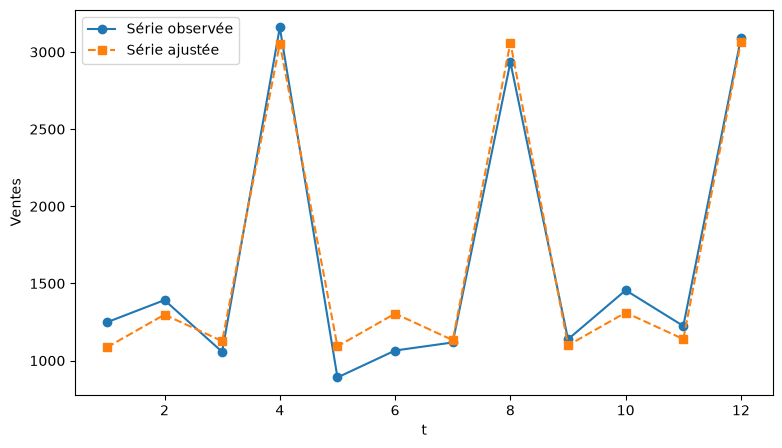

In [20]:
# Prédictions (= valeurs ajustées)
Y_pred = D @ estimation
print(Y_pred)

#coefficients

a = estimation[0] #= coefficient devant le temps 
b = np.mean(estimation[1:]) # Moyenne des coefficients saisonniers estimés.

saison = estimation[1:] - b  # calcul de la saisonnalité de la série

# Visualisation des résultats : comparer la série initiale et la série Y_pred

print(a, b, saison)

# Graphique
plt.figure(figsize=(9, 5))
plt.plot(time, Y, 'o-', label='Série observée')
plt.plot(time, Y_pred, 's--', label='Série ajustée')
plt.xlabel('t')
plt.ylabel('Ventes')
plt.legend()
plt.show()
